In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

file_path = 'Nigeria_Transport_Analytics_Dataset.csv'


In [2]:
import pandas as pd
df = pd.read_csv("Nigeria_Transport_Analytics_Dataset.csv")
print(df.head(10))
print(df.tail(5))
print(df.shape)          # (240, 23)
print(df.columns.tolist())
print(df.dtypes)
print(df.isnull().sum()) # all 0

   Trip_ID Travel_Date    Origin_City      Origin_Terminal Destination_City  \
0  TRP-001  2026-01-04           Kano            Nassarawa              Jos   
1  TRP-002  2026-01-07          Akure             Alagbaka    Port Harcourt   
2  TRP-003  2026-01-10          Lagos              Badagry            Lagos   
3  TRP-004  2026-01-13          Enugu  Independence Layout           Ilorin   
4  TRP-005  2026-01-16         Owerri           New Owerri            Abuja   
5  TRP-006  2026-01-19          Abuja                Kubwa           Owerri   
6  TRP-007  2026-01-22         Ilorin                Tanke            Enugu   
7  TRP-008  2026-01-25          Lagos                 Yaba            Lagos   
8  TRP-009  2026-01-28  Port Harcourt                Diobu            Akure   
9  TRP-010  2026-01-31            Jos             Terminus             Kano   

  Destination_Terminal Transport_Mode Vehicle_ID Travel_Period     Weather  \
0             Terminus            BRT    VEH-024    

In [3]:
# Group by Transport_Mode and calculate the required metrics
mode_analysis = df.groupby('Transport_Mode').agg(
    Number_of_Trips=('Trip_ID', 'count'),
    Total_Passengers=('Passenger_Count', 'sum'),
    Average_Fare=('Fare_per_Passenger_NGN', 'mean'),
    Average_Rating=('Customer_Rating', 'mean')
).round(2)

print(mode_analysis)

# Identify the mode with the highest total passengers
highest_mode = mode_analysis['Total_Passengers'].idxmax()
highest_passengers = mode_analysis['Total_Passengers'].max()

print(f"\nTransport mode with the highest total passengers: {highest_mode} ({highest_passengers} passengers)")

                Number_of_Trips  Total_Passengers  Average_Fare  \
Transport_Mode                                                    
BRT                          36              1557       1334.72   
Bus                          43               473       1126.74   
Minibus                      35               306       1180.00   
Motorcycle                   45                45       2445.56   
Taxi                         45               108       5761.11   
Tricycle                     36                63       1100.00   

                Average_Rating  
Transport_Mode                  
BRT                       3.98  
Bus                       4.00  
Minibus                   4.04  
Motorcycle                3.99  
Taxi                      4.01  
Tricycle                  4.00  

Transport mode with the highest total passengers: BRT (1557 passengers)


In [6]:
df["Profit_NGN"] = df["Total_Revenue_NGN"] - df["Operating_Cost_NGN"]

In [7]:
# Calculate totals
print("Total Revenue:", df["Total_Revenue_NGN"].sum())
print("Total Operating Cost:", df["Operating_Cost_NGN"].sum())
print("Total Profit:", df["Profit_NGN"].sum())

# Profit by transport mode (highest and lowest)
print(df.groupby("Transport_Mode")["Profit_NGN"].sum().sort_values(ascending=False))

Total Revenue: 3800700
Total Operating Cost: 2768000
Total Profit: 1032700
Transport_Mode
BRT           1149600
Taxi           203450
Bus            -27300
Minibus        -59650
Motorcycle     -79550
Tricycle      -153850
Name: Profit_NGN, dtype: int64


In [8]:
# Average and maximum delay
print("Average Delay (min):", round(df["Delay_min"].mean(), 2))
print("Maximum Delay (min):", df["Delay_min"].max())

# Count of trip statuses
print("\nTrip Status Counts:")
print(df["Trip_Status"].value_counts())

# Weather and road conditions linked to longest delays
print("\nAverage Delay by Weather and Road Condition:")
print(df.groupby(["Weather", "Road_Condition"])["Delay_min"].mean().sort_values(ascending=False))

Average Delay (min): 37.88
Maximum Delay (min): 242

Trip Status Counts:
Trip_Status
Severely Delayed    100
On Time              93
Delayed              47
Name: count, dtype: int64

Average Delay by Weather and Road Condition:
Weather     Road_Condition
Light Rain  Poor              115.750000
            Fair               90.000000
Heavy Rain  Poor               59.375000
Light Rain  Good               56.812500
Clear       Poor               55.791667
Heavy Rain  Fair               41.875000
Clear       Fair               32.333333
Heavy Rain  Good               24.625000
Clear       Good               23.916667
Cloudy      Poor               19.250000
            Fair                4.687500
            Good                0.562500
Name: Delay_min, dtype: float64


In [10]:
# Create Occupancy Rate
df["Occupancy_Rate"] = (df["Passenger_Count"] / df["Vehicle_Capacity"]) * 100

# Average occupancy by transport mode
print("Average Occupancy Rate by Transport Mode:")
print(df.groupby("Transport_Mode")["Occupancy_Rate"].mean().sort_values(ascending=False).round(2))

# Trips above 90% occupancy
high_occupancy = df[df["Occupancy_Rate"] > 90]
print("\nNumber of trips above 90% occupancy:", len(high_occupancy))
print(high_occupancy[["Trip_ID", "Transport_Mode", "Passenger_Count", "Vehicle_Capacity", "Occupancy_Rate"]])

Average Occupancy Rate by Transport Mode:
Transport_Mode
Motorcycle    100.00
Minibus        62.45
BRT            61.79
Bus            61.11
Taxi           60.00
Tricycle       58.33
Name: Occupancy_Rate, dtype: float64

Number of trips above 90% occupancy: 45
     Trip_ID Transport_Mode  Passenger_Count  Vehicle_Capacity  Occupancy_Rate
1    TRP-002     Motorcycle                1                 1           100.0
7    TRP-008     Motorcycle                1                 1           100.0
8    TRP-009     Motorcycle                1                 1           100.0
14   TRP-015     Motorcycle                1                 1           100.0
21   TRP-022     Motorcycle                1                 1           100.0
28   TRP-029     Motorcycle                1                 1           100.0
34   TRP-035     Motorcycle                1                 1           100.0
35   TRP-036     Motorcycle                1                 1           100.0
41   TRP-042     Motorcycle 

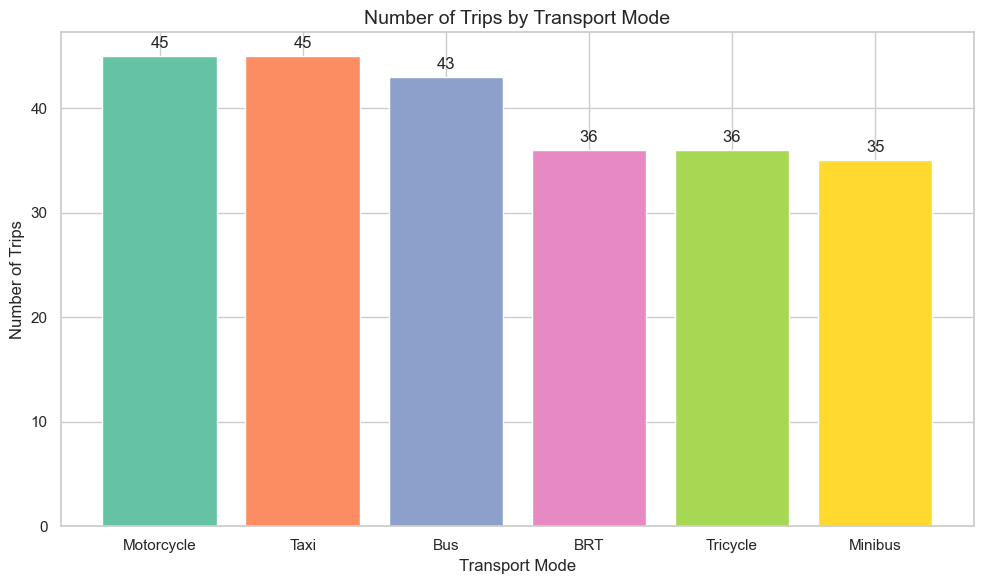

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count trips by transport mode
trip_counts = df["Transport_Mode"].value_counts()

# Create the bar chart
plt.figure(figsize=(10, 6))
bars = plt.bar(trip_counts.index, trip_counts.values, 
               color=sns.color_palette("Set2", len(trip_counts)))

# Add title and labels
plt.title("Number of Trips by Transport Mode", fontsize=14)
plt.xlabel("Transport Mode", fontsize=12)
plt.ylabel("Number of Trips", fontsize=12)

# Add data labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.5,
             str(int(height)), ha="center", va="bottom")

plt.tight_layout()
plt.show()

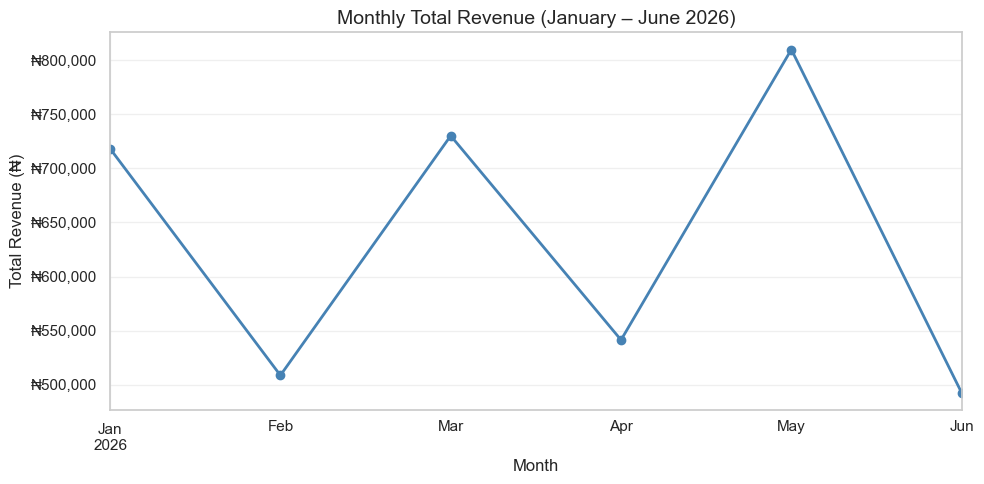

Highest revenue month: 2026-05 → ₦809,800


In [12]:
# Convert Travel_Date to datetime
df["Travel_Date"] = pd.to_datetime(df["Travel_Date"])

# Calculate monthly total revenue
monthly_revenue = df.groupby(df["Travel_Date"].dt.to_period("M"))["Total_Revenue_NGN"].sum()

# Create the line chart
plt.figure(figsize=(10, 5))
monthly_revenue.plot(marker="o", linewidth=2, color="steelblue")

plt.title("Monthly Total Revenue (January – June 2026)", fontsize=14)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Revenue (₦)", fontsize=12)

# Format y-axis with Naira symbol
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"₦{x:,.0f}"))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Show the highest revenue month
print("Highest revenue month:", monthly_revenue.idxmax(), "→ ₦{:,}".format(monthly_revenue.max()))

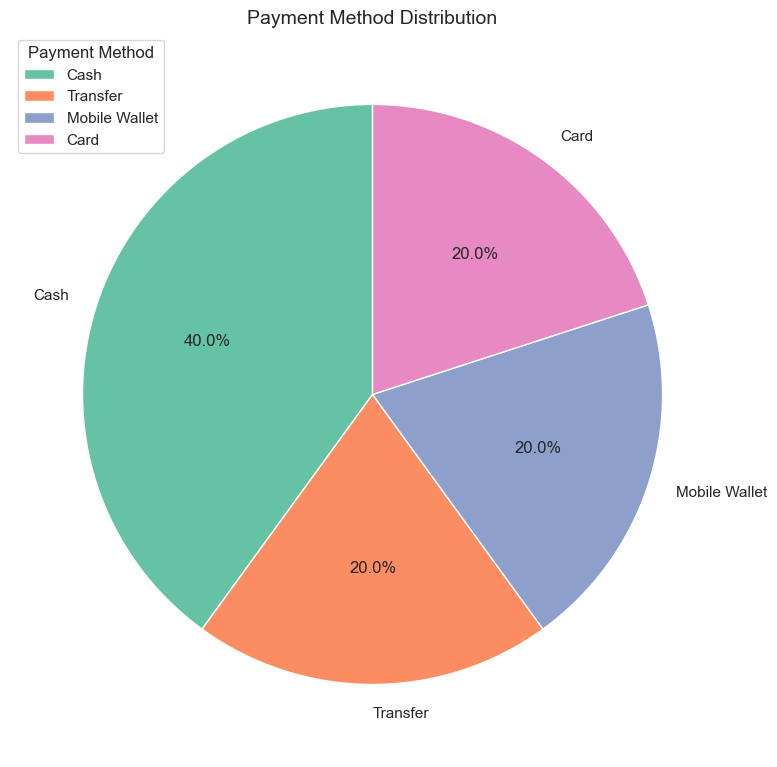

Most used payment method: Cash


In [13]:
import matplotlib.pyplot as plt

# Count payment methods
payment_counts = df["Payment_Method"].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))
plt.pie(payment_counts, 
        labels=payment_counts.index, 
        autopct="%1.1f%%",
        colors=["#66c2a5", "#fc8d62", "#8da0cb", "#e78ac3"],
        startangle=90)

plt.title("Payment Method Distribution", fontsize=14)
plt.legend(title="Payment Method", loc="best")
plt.tight_layout()
plt.show()

print("Most used payment method:", payment_counts.idxmax())

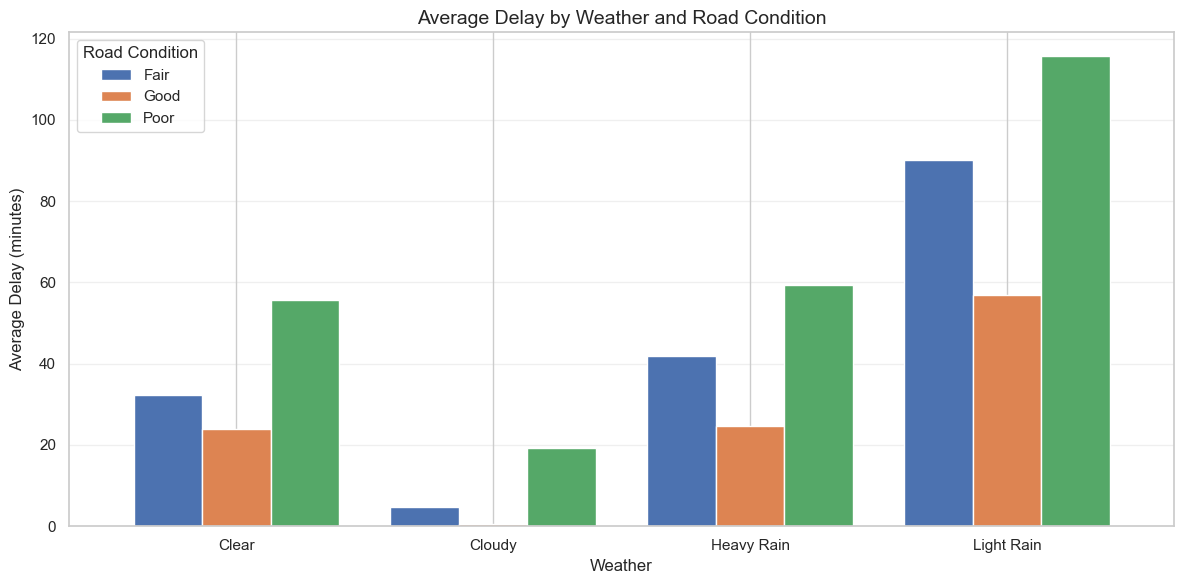

In [14]:
import seaborn as sns

# Calculate average delay for each Weather + Road_Condition combination
avg_delay = df.groupby(["Weather", "Road_Condition"])["Delay_min"].mean().unstack()

# Create grouped bar chart
avg_delay.plot(kind="bar", figsize=(12, 6), width=0.8)

plt.title("Average Delay by Weather and Road Condition", fontsize=14)
plt.xlabel("Weather", fontsize=12)
plt.ylabel("Average Delay (minutes)", fontsize=12)
plt.legend(title="Road Condition")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

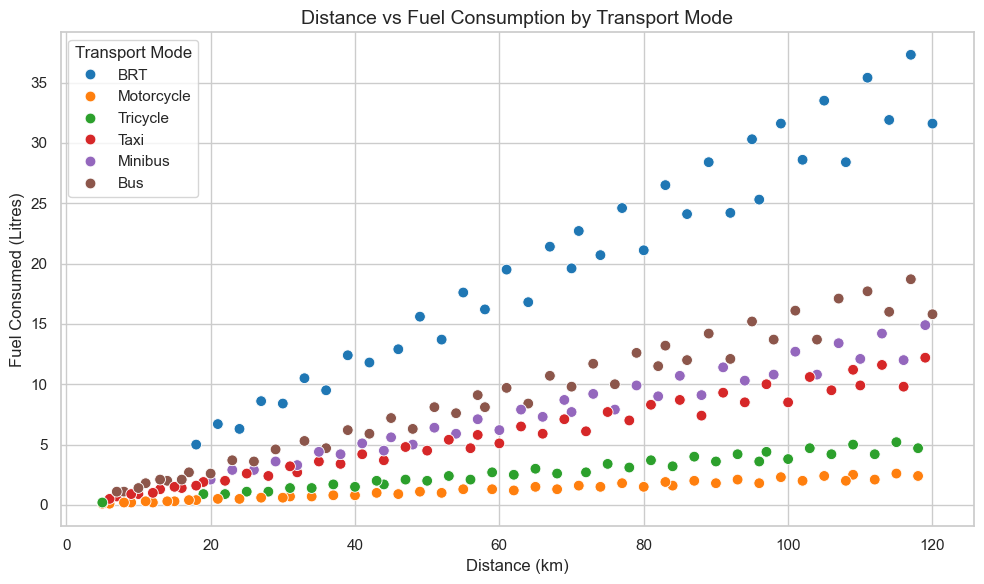

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, 
                x="Distance_km", 
                y="Fuel_Consumed_L", 
                hue="Transport_Mode", 
                palette="tab10", 
                s=60)

plt.title("Distance vs Fuel Consumption by Transport Mode", fontsize=14)
plt.xlabel("Distance (km)", fontsize=12)
plt.ylabel("Fuel Consumed (Litres)", fontsize=12)
plt.legend(title="Transport Mode")
plt.tight_layout()
plt.show()